# PRC Data Challenge 2026 -- Taxi-out time: Exploratory Data Analysis

Scope of this notebook: taxi-time distribution, anomalous values, missing data,
monthly patterns, and the main airports / runways / aircraft types in the 2025
training data.

Not in scope here (covered separately): the timestamp/target-leakage audit
lives in `Mode2Test/solution/stage1_audit.py` (the "AOBT_3 near-target proxy"
check) -- this notebook is the plain-EDA companion, not a re-run of that audit.

Data is read directly from `../prc-2026-datasets/` (git-ignored; see the repo
README for how to obtain it -- access is credentialed/team-scoped).


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

DATA_DIR = Path("..") / "prc-2026-datasets"
assert DATA_DIR.exists(), f"expected data at {DATA_DIR.resolve()}"
train_files = sorted(DATA_DIR.glob("training_*.parquet"))
print(f"{len(train_files)} monthly training files")
for f in train_files:
    print(" ", f.name)


12 monthly training files
  training_2025-01-01_2025-02-01.parquet
  training_2025-02-01_2025-03-01.parquet
  training_2025-03-01_2025-04-01.parquet
  training_2025-04-01_2025-05-01.parquet
  training_2025-05-01_2025-06-01.parquet
  training_2025-06-01_2025-07-01.parquet
  training_2025-07-01_2025-08-01.parquet
  training_2025-08-01_2025-09-01.parquet
  training_2025-09-01_2025-10-01.parquet
  training_2025-10-01_2025-11-01.parquet
  training_2025-11-01_2025-12-01.parquet
  training_2025-12-01_2026-01-01.parquet


## 1. Load the data

Movement-level columns only (skip the heavier flight-plan text fields we don't need for EDA).

In [2]:
COLS = [
    "MVT_ID_mvt", "ADEP_mvt", "ADES_mvt", "PHASE_mvt", "MVT_TIME_UTC_mvt",
    "AIRCRAFT_TYPE_mvt", "RUNWAY_mvt", "STAND_mvt", "TAXITIME_SEC_mvt",
]

frames = []
for f in train_files:
    df = pd.read_parquet(f, columns=COLS)
    df["source_file"] = f.name
    frames.append(df)
raw = pd.concat(frames, ignore_index=True)
print("raw shape:", raw.shape)
raw.head()


raw shape: (4167797, 10)


,MVT_ID_mvt,ADEP_mvt,ADES_mvt,PHASE_mvt,MVT_TIME_UTC_mvt,AIRCRAFT_TYPE_mvt,RUNWAY_mvt,STAND_mvt,TAXITIME_SEC_mvt,source_file
0,182234017.0,EDDF,EIDW,DEP,2025-01-07 21:10:06+00:00,A320,25C,B41,595.0,training_2025-01-01_2025-02-01.parquet
1,182249437.0,EPWA,EDDF,ARR,2025-01-07 21:10:32+00:00,E75S,25C,V115,505.0,training_2025-01-01_2025-02-01.parquet
2,182234011.0,EDDF,VHHH,DEP,2025-01-07 21:11:23+00:00,A346,18,A20,1085.0,training_2025-01-01_2025-02-01.parquet
3,182234021.0,EDDF,EGBB,DEP,2025-01-07 21:12:29+00:00,A320,25C,B48,688.0,training_2025-01-01_2025-02-01.parquet
4,182249434.0,EDDM,EDDF,ARR,2025-01-07 21:13:01+00:00,A320,25C,A17,313.0,training_2025-01-01_2025-02-01.parquet


In [3]:
raw["month"] = pd.to_datetime(raw["MVT_TIME_UTC_mvt"]).dt.to_period("M").astype(str)
print("date range:", raw["MVT_TIME_UTC_mvt"].min(), "->", raw["MVT_TIME_UTC_mvt"].max())
print()
print("PHASE_mvt counts:")
print(raw["PHASE_mvt"].value_counts())


date range: 2025-01-01 00:01:04+00:00 -> 2025-12-31 23:57:36+00:00

PHASE_mvt counts:
PHASE_mvt
DEP    2085047
ARR    2082750
Name: count, dtype: int64


## 2. Taxi-time distribution

`TAXITIME_SEC_mvt` (the target) is only defined on departure legs (`PHASE_mvt == "DEP"`).
Everything below filters to `dep`.


In [4]:
dep = raw[raw["PHASE_mvt"].eq("DEP")].copy()
print(f"departure rows: {len(dep):,} of {len(raw):,} total ({len(dep) / len(raw):.1%})")

y = dep["TAXITIME_SEC_mvt"]
print()
print(y.describe())
print()
pcts = [0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]
print("percentiles (seconds):")
print(y.quantile(pcts))


departure rows: 2,085,047 of 4,167,797 total (50.0%)

count    2.085047e+06
mean     9.912007e+02
std      5.463598e+02
min     -1.200000e+01
25%      7.190000e+02
50%      9.120000e+02
75%      1.188000e+03
max      1.311670e+05
Name: TAXITIME_SEC_mvt, dtype: float64

percentiles (seconds):
0.001     119.0
0.010     291.0
0.050     480.0
0.250     719.0
0.500     912.0
0.750    1188.0
0.950    1684.0
0.990    2339.0
0.999    4501.0
Name: TAXITIME_SEC_mvt, dtype: float64


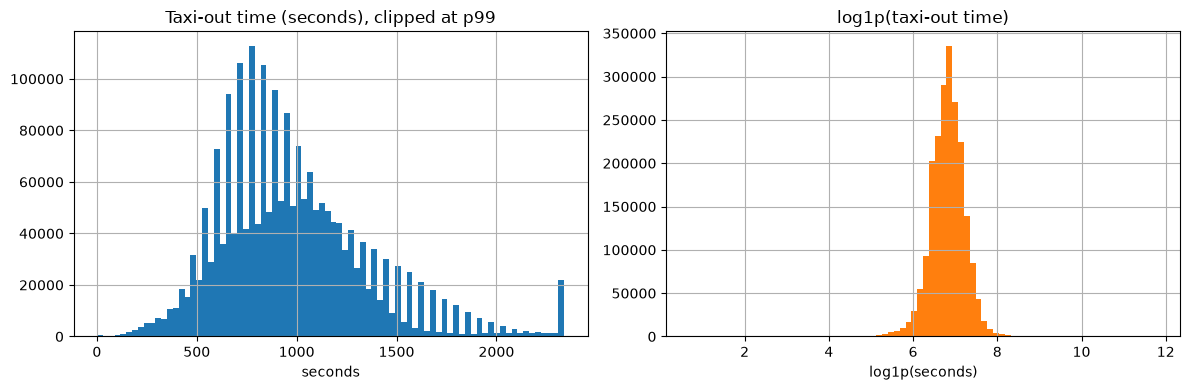

median 912s (~15.2 min), p95 1684s, p99 2339s


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
finite = y[np.isfinite(y) & (y > 0)]

axes[0].hist(finite.clip(upper=finite.quantile(0.99)), bins=80)
axes[0].set_title("Taxi-out time (seconds), clipped at p99")
axes[0].set_xlabel("seconds")

axes[1].hist(np.log1p(finite), bins=80, color="tab:orange")
axes[1].set_title("log1p(taxi-out time)")
axes[1].set_xlabel("log1p(seconds)")
plt.tight_layout()
plt.show()

print(f"median {finite.median():.0f}s (~{finite.median()/60:.1f} min), "
      f"p95 {finite.quantile(0.95):.0f}s, p99 {finite.quantile(0.99):.0f}s")


## 3. Anomalous values

In [6]:
n = len(dep)
n_null = int(y.isna().sum())
n_le_0 = int((y <= 0).sum())
n_neg = int((y < 0).sum())
# a very generous upper sanity bound -- taxi-out beyond 2 hours is not physically
# impossible (deicing queues, ground stops) but is worth a look, not an assumption
# it's an error
n_gt_2h = int((y > 7200).sum())

print(f"total DEP rows           : {n:,}")
print(f"null target              : {n_null:,} ({n_null / n:.4%})")
print(f"target <= 0              : {n_le_0:,} ({n_le_0 / n:.4%})")
print(f"  of which strictly < 0  : {n_neg:,}")
print(f"target > 7200s (2h)      : {n_gt_2h:,} ({n_gt_2h / n:.4%})")


total DEP rows           : 2,085,047
null target              : 0 (0.0000%)
target <= 0              : 388 (0.0186%)
  of which strictly < 0  : 369
target > 7200s (2h)      : 584 (0.0280%)


In [7]:
if n_le_0:
    display(dep.loc[y <= 0, ["MVT_ID_mvt", "ADEP_mvt", "MVT_TIME_UTC_mvt", "TAXITIME_SEC_mvt"]].head(10))
else:
    print("no non-positive taxi times")


,MVT_ID_mvt,ADEP_mvt,MVT_TIME_UTC_mvt,TAXITIME_SEC_mvt
137776,182977114.0,LEBL,2025-01-15 00:54:57+00:00,-8.0
187295,182379342.0,LFPG,2025-01-03 20:27:54+00:00,-11.0
192353,182363682.0,LFPG,2025-01-14 11:26:56+00:00,-8.0
192383,182364760.0,LFPG,2025-01-10 00:44:59+00:00,-1.0
198600,182374475.0,LFPG,2025-01-08 08:58:59+00:00,-2.0
199654,182363165.0,LFPG,2025-01-08 09:47:55+00:00,-9.0
207982,182364767.0,LFPG,2025-01-21 00:53:59+00:00,-2.0
208339,182368293.0,LFPG,2025-01-21 03:35:54+00:00,-12.0
208477,182364769.0,LFPG,2025-01-23 00:46:59+00:00,-2.0
209089,182364765.0,LFPG,2025-01-17 00:45:54+00:00,-11.0


In [8]:
print("largest 10 taxi-out times:")
display(dep.nlargest(10, "TAXITIME_SEC_mvt")[
    ["MVT_ID_mvt", "ADEP_mvt", "RUNWAY_mvt", "MVT_TIME_UTC_mvt", "TAXITIME_SEC_mvt"]
])


largest 10 taxi-out times:


,MVT_ID_mvt,ADEP_mvt,RUNWAY_mvt,MVT_TIME_UTC_mvt,TAXITIME_SEC_mvt
534565,183903219.0,LIRF,25,2025-02-11 17:51:03+00:00,131167.0
1924280,190199540.0,LIRF,25,2025-06-25 16:03:06+00:00,88392.0
2310186,192626268.0,LIRF,25,2025-07-21 08:28:56+00:00,88132.0
4090207,201198951.0,LIRF,25,2025-12-28 18:35:02+00:00,87605.0
3764440,200300302.0,LIRF,25,2025-11-12 12:14:59+00:00,87598.0
3064204,196129531.0,LIRF,34L,2025-09-28 22:38:01+00:00,87543.0
3751502,200297323.0,LIRF,34L,2025-11-04 13:22:00+00:00,87480.0
2287231,192615553.0,LIRF,25,2025-07-03 17:01:00+00:00,87361.0
1577123,188253302.0,LSZH,28,2025-05-14 14:55:39+00:00,87341.0
854507,185042445.0,LIRF,25,2025-03-28 10:41:03+00:00,87247.0


## 4. Missing data

Null fraction per column, on the departure rows (the rows the target is scored on).

,null_fraction
AIRCRAFT_TYPE_mvt,0.000723
ADES_mvt,0.000059
STAND_mvt,0.000013
MVT_ID_mvt,0.000000
ADEP_mvt,0.000000
MVT_TIME_UTC_mvt,0.000000
PHASE_mvt,0.000000
RUNWAY_mvt,0.000000
TAXITIME_SEC_mvt,0.000000


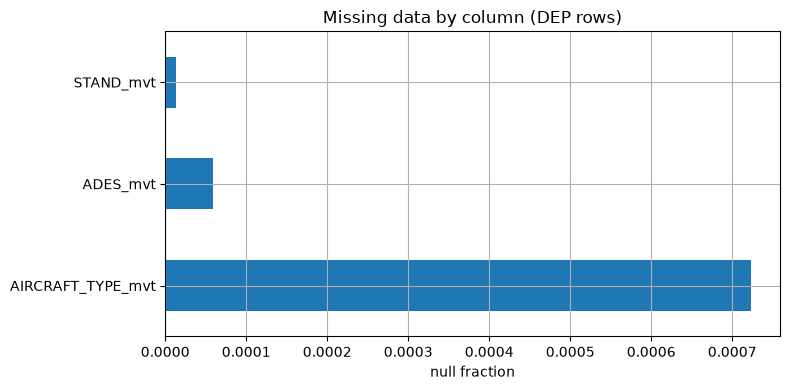

In [9]:
null_frac = dep[COLS].isna().mean().sort_values(ascending=False)
display(null_frac.to_frame("null_fraction"))

fig, ax = plt.subplots(figsize=(8, 4))
null_frac[null_frac > 0].plot.barh(ax=ax)
ax.set_xlabel("null fraction")
ax.set_title("Missing data by column (DEP rows)")
plt.tight_layout()
plt.show()


## 5. Monthly patterns

,count,mean,median,std
month,,,,
2025-01,153706,995.292526,906.0,604.833035
2025-02,143732,1002.371427,904.0,628.324782
2025-03,164449,972.002207,905.0,461.685385
2025-04,175288,971.418597,908.0,436.042679
2025-05,185202,986.614902,925.0,469.395070
2025-06,183142,973.231334,902.0,554.929975
2025-07,190713,1025.733243,948.0,745.010729
2025-08,191182,993.764261,929.0,533.826163
2025-09,183950,989.783914,914.0,560.335935


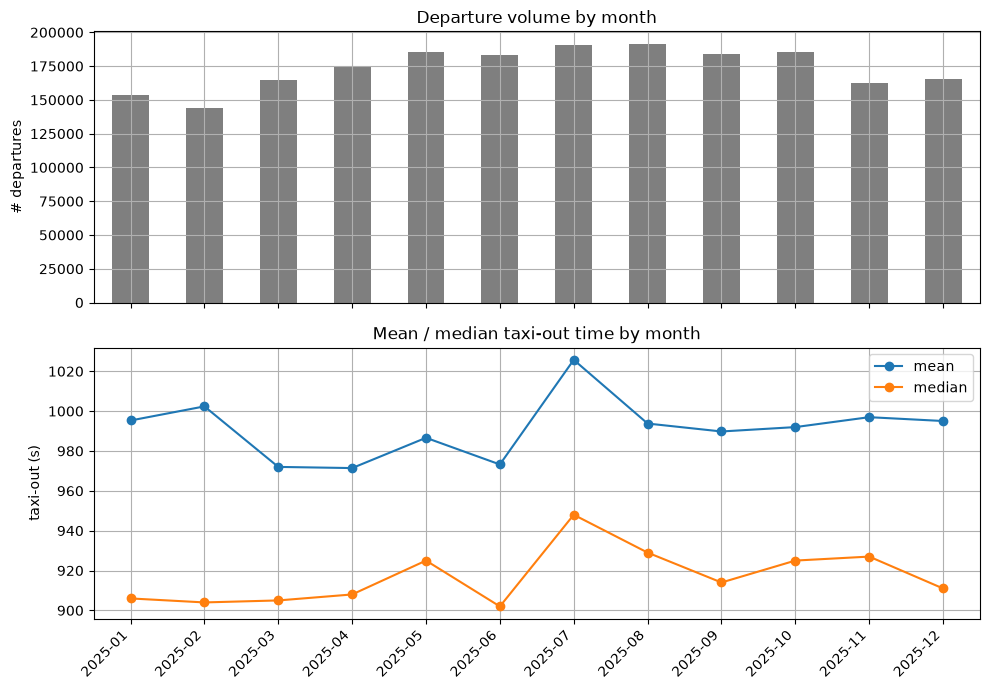

In [10]:
monthly = dep.groupby("month")["TAXITIME_SEC_mvt"].agg(["count", "mean", "median", "std"])
display(monthly)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
monthly["count"].plot.bar(ax=axes[0], color="tab:gray")
axes[0].set_ylabel("# departures")
axes[0].set_title("Departure volume by month")

axes[1].plot(monthly.index, monthly["mean"], marker="o", label="mean")
axes[1].plot(monthly.index, monthly["median"], marker="o", label="median")
axes[1].set_ylabel("taxi-out (s)")
axes[1].set_title("Mean / median taxi-out time by month")
axes[1].legend()
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 6. Main airports

10 distinct departure airports


,n_departures
ADEP_mvt,
LTFM,272965
EHAM,247951
LFPG,239552
EGLL,239546
EDDF,230141
LEMD,212242
LEBL,179705
EDDM,167334
LIRF,160704


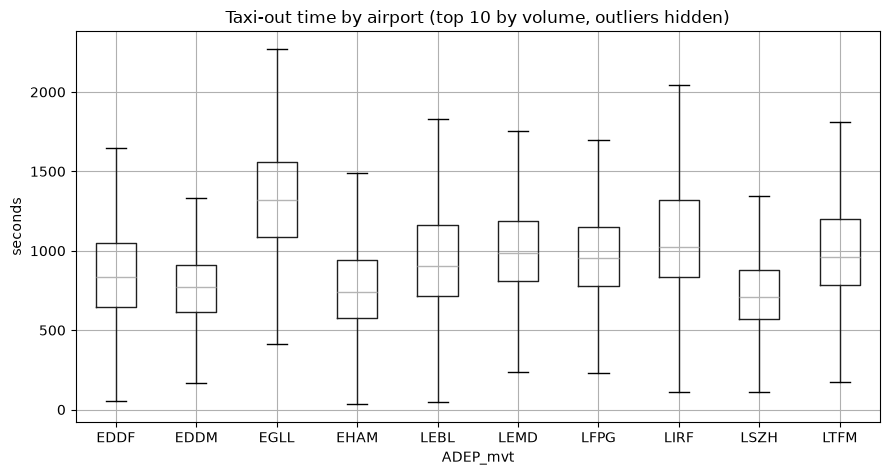

In [11]:
airport_vol = dep["ADEP_mvt"].value_counts()
print(f"{dep['ADEP_mvt'].nunique()} distinct departure airports")
display(airport_vol.to_frame("n_departures"))

top_airports = airport_vol.head(10).index.tolist()

fig, ax = plt.subplots(figsize=(9, 5))
dep[dep["ADEP_mvt"].isin(top_airports)].boxplot(
    column="TAXITIME_SEC_mvt", by="ADEP_mvt", ax=ax,
    showfliers=False,
)
ax.set_title("Taxi-out time by airport (top 10 by volume, outliers hidden)")
plt.suptitle("")
ax.set_ylabel("seconds")
plt.tight_layout()
plt.show()


## 7. Runways

Runway codes are only meaningful within an airport, so the key is `airport|runway`.

,n_departures
adep_runway,
LIRF|25,144747
EDDF|18,140022
LTFM|36,126157
LEBL|24L,124514
EGLL|09R,87565
EHAM|24,85236
LSZH|28,84800
LEMD|36R,84705
LEMD|36L,84203


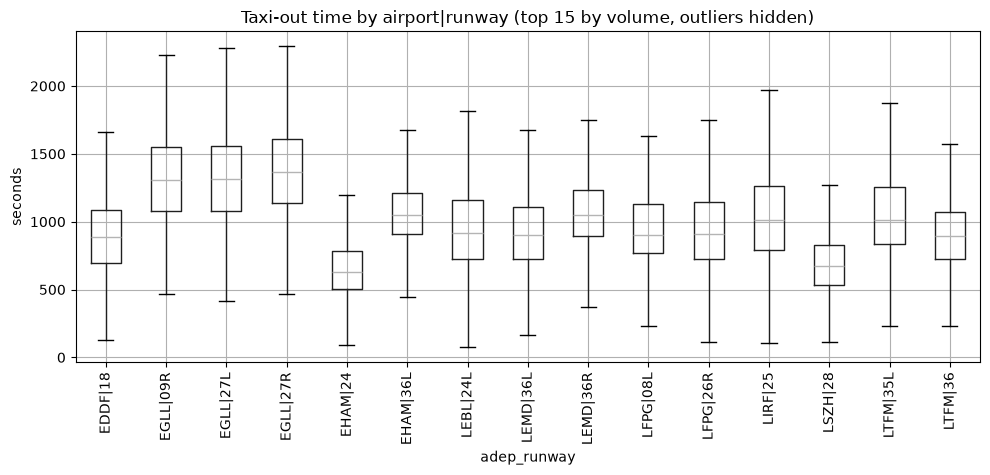

In [12]:
dep["adep_runway"] = dep["ADEP_mvt"].astype(str) + "|" + dep["RUNWAY_mvt"].astype(str)
rwy_vol = dep["adep_runway"].value_counts().head(15)
display(rwy_vol.to_frame("n_departures"))

fig, ax = plt.subplots(figsize=(10, 5))
dep[dep["adep_runway"].isin(rwy_vol.index)].boxplot(
    column="TAXITIME_SEC_mvt", by="adep_runway", ax=ax, showfliers=False, rot=90,
)
ax.set_title("Taxi-out time by airport|runway (top 15 by volume, outliers hidden)")
plt.suptitle("")
ax.set_ylabel("seconds")
plt.tight_layout()
plt.show()


## 8. Aircraft types

,n_departures
AIRCRAFT_TYPE_mvt,
A320,342973
B738,218514
A20N,169768
A321,162231
A21N,149245
A319,134678
E190,78863
BCS3,77321
B77W,67204


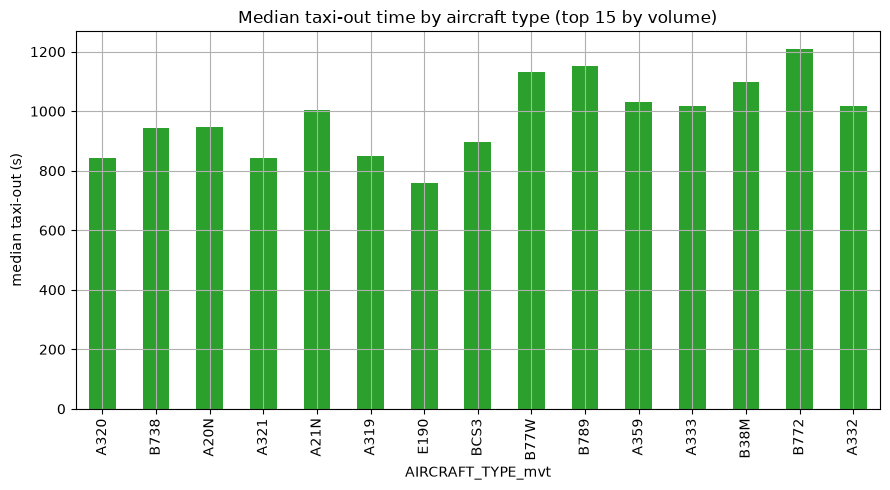

In [13]:
ac_vol = dep["AIRCRAFT_TYPE_mvt"].value_counts().head(15)
display(ac_vol.to_frame("n_departures"))

med_by_ac = (
    dep[dep["AIRCRAFT_TYPE_mvt"].isin(ac_vol.index)]
    .groupby("AIRCRAFT_TYPE_mvt")["TAXITIME_SEC_mvt"]
    .median()
    .reindex(ac_vol.index)
)

fig, ax = plt.subplots(figsize=(9, 5))
med_by_ac.plot.bar(ax=ax, color="tab:green")
ax.set_ylabel("median taxi-out (s)")
ax.set_title("Median taxi-out time by aircraft type (top 15 by volume)")
plt.tight_layout()
plt.show()


## 9. Summary -- fill in after running

- Distribution: right-skewed, median ~ *(see cell 2 output)*, long tail past p99.
- Anomalies: report the exact null/`<=0`/`>2h` counts printed in section 3 here.
- Missing data: name the columns with non-zero null fraction from section 4 and note whether it's structural (e.g. only certain airports report a field) or random.
- Monthly: note any trend/seasonality visible in section 5, and any month with a volume outlier worth flagging before it's used in a time-based split.
- Airports/runways/aircraft: name the 2-3 airports dominating the scored volume, and whether taxi-out spread differs enough by runway/aircraft type to justify per-airport or per-aircraft modeling later.

(Leave this section for whoever runs the notebook to fill in with the printed numbers -- deliberately not pre-filled with invented figures.)
